In [1]:
# produce the original scattering dataset
import os
import numpy as np
import torch
from torch.utils.data import Dataset
from torchvision import transforms
import matplotlib.pyplot as plt
# from torch.fft import fft2, ifft2, fftshift, ifftshift
from scipy.fftpack import fft2, ifft2, fftshift, ifftshift
from ipywidgets import interact, IntSlider

from tqdm import tqdm


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## FFT Functions
def FFT(x):
    return fftshift(fft2(ifftshift(x), axes=(0,1)), axes=(0,1))

def iFFT(x):
    return fftshift(ifft2(ifftshift(x, axes=(0,1)), axes=(0,1)), axes=(0,1))


In [22]:
# Shape of input field
s_in = [32, 32]

## Generate a random phase for the media
random_matrix = np.random.rand(int(s_in[0]*s_in[1]), int(s_in[0]*s_in[1]))
random_phase = np.exp(2*1j*np.pi * random_matrix)
np.savetxt('random_matrix.txt', random_matrix)

In [2]:
# parameters

subdir = 'Dataset/'
nimages = [10000, 500]
folders = ['train', 'test']

In [3]:
def calculate_speckle(input_field):
    a = np.dot(random_phase,input_field.flatten()).reshape(s_in)

    xx, yy = np.meshgrid(np.linspace(0, input_field.shape[0]-1, input_field.shape[0]), np.linspace(0, input_field.shape[1]-1, input_field.shape[1]))
    pupil = np.ones_like(input_field)
    pupil[(xx-input_field.shape[0]/2)**2 + (yy-input_field.shape[1]/2)**2 <= (input_field.shape[0]/2)**2] = 1

    # b = FFT(a*pupil)
    img_shape = [400, 400]
    b = FFT(np.pad(a*pupil, [int(img_shape[0]/2 - input_field.shape[0]/2), int(img_shape[1]/2 - input_field.shape[1]/2)]))
    b = abs(b)**2
    b /= np.max(b)
    b *= 255
    b_down = b.reshape(100, 4, 100, 4).mean(axis=(1, 3))
    return b_down
  

def bin_image(image, bin_size=2):
    # Get the dimensions of the original image
    height, width = image.shape
    
    # Calculate the dimensions of the binned image
    new_height, new_width = height // bin_size, width // bin_size
    
    # Create an empty array to store the binned image
    binned_image = np.zeros((new_height, new_width))
    
    # Loop through each block and compute the average
    for i in range(new_height):
        for j in range(new_width):
            block = image[i*bin_size:(i+1)*bin_size, j*bin_size:(j+1)*bin_size]
            binned_image[i, j] = np.mean(block)
    
    return binned_image

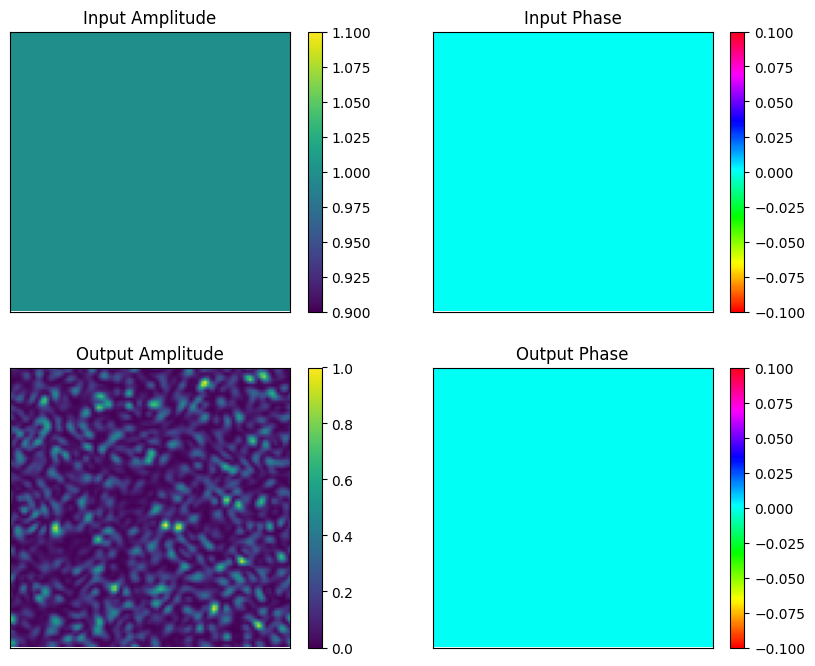

In [7]:
s_in = [32, 32]
#input_field = np.random.randint(0, 2,(s_in))*np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in))
input_field = np.ones(s_in)
#input_field = np.random.randint(0, 256,(s_in))*np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in))
# random input in spectrum
matrix = np.loadtxt('random_matrix.txt')
random_phase = np.exp(2*1j*np.pi * matrix)
b = calculate_speckle(input_field)
Output = (b - b.min()) / (b.max() - b.min() + 1e-8)

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(np.abs(input_field))
plt.title("Input Amplitude")
plt.xticks([])
plt.yticks([])
plt.colorbar()

plt.subplot(2, 2, 2)
plt.imshow(np.angle(input_field), cmap='hsv')
plt.title("Input Phase")
plt.xticks([])
plt.yticks([])
plt.colorbar()

plt.subplot(2, 2, 3)
plt.imshow(Output)
plt.title("Output Amplitude")
plt.colorbar()
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(np.angle(b), cmap='hsv')
plt.title("Output Phase")
plt.colorbar()
plt.xticks([])
plt.yticks([])

plt.savefig("Input-Output.png", dpi=400, bbox_inches="tight")
plt.show()


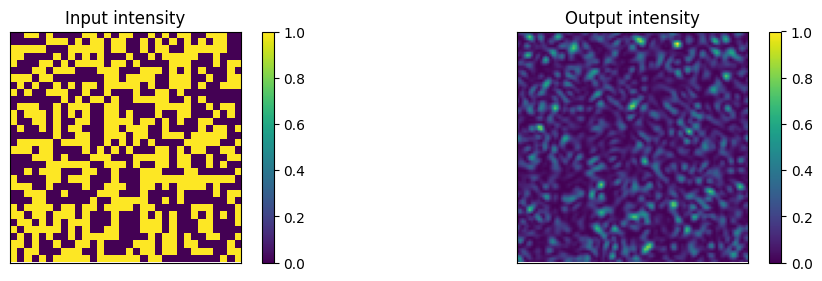

In [5]:

input_field = np.random.randint(0, 2,(s_in))*np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in))
#input_field = np.random.randint(0, 256,(s_in))*np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in))
# random input in spectrum
matrix = np.loadtxt('random_matrix.txt')
random_phase = np.exp(2*1j*np.pi * matrix)
b = calculate_speckle(input_field)
Output = (b - b.min()) / (b.max() - b.min() + 1e-8)

plt.figure(figsize=(12, 3))
plt.subplot(1, 2, 1)
plt.imshow(np.abs(input_field))
plt.title("Input intensity")
plt.xticks([])
plt.yticks([])
plt.colorbar()
plt.subplot(1, 2, 2)
plt.imshow(Output)
plt.title("Output intensity")
plt.colorbar()
plt.xticks([])
plt.yticks([])

plt.savefig("Input-Output.png", dpi=400, bbox_inches="tight")
plt.show()


In [33]:
print(np.iscomplexobj(input_field))

True


In [34]:
if not os.path.exists(subdir):
    os.mkdir(subdir)
    
for i, prefix in enumerate(folders):
    i_dir = subdir + '/' + prefix + '/'
    if not os.path.exists(i_dir):
        os.mkdir(i_dir)
        in_images_dir = i_dir + '/' + 'in_images' + '/'
        out_images_dir = i_dir + '/' + 'out_images'+ '/'
        os.mkdir(in_images_dir)
        os.mkdir(out_images_dir)
    else:
        in_images_dir = i_dir + '/' + 'in_images' + '/'
        out_images_dir = i_dir + '/' + 'out_images'+ '/'

    for n in tqdm(range(nimages[folders.index(prefix)])):
        input_field = np.random.randint(0, 2,(s_in))
        # *np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in))
        ouput = calculate_speckle(input_field)

        name_in = in_images_dir+ '/' + str(n) + '.png'
        name_out = out_images_dir+ '/' + str(n) + '.png'
        plt.imsave(name_in, input_field*255, cmap='gray')
        plt.imsave(name_out, ouput, cmap='gray')

100%|██████████| 500/500 [00:04<00:00, 107.00it/s]


In [35]:

input_field = np.random.randint(0, 2,(s_in))
random_phase.shape

(1024, 1024)

In [17]:
input_field = np.random.randint(0, 2, s_in) * np.exp(1j * np.random.rand(*s_in) * 2 * np.pi)

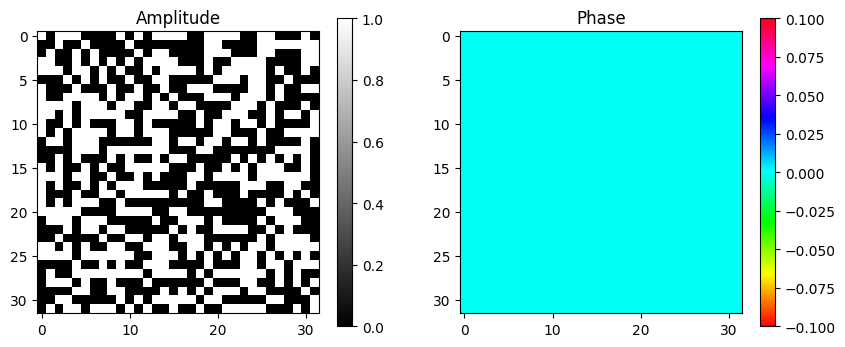

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(input_field), cmap='gray')
plt.title("Amplitude")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(np.angle(input_field), cmap='hsv')
plt.title("Phase")
plt.colorbar()

plt.show()

In [20]:
input_field = np.random.randint(0, 2, s_in)* np.exp(1j *np.exp(1j*np.random.rand(1)*2*np.pi*np.ones(s_in)))

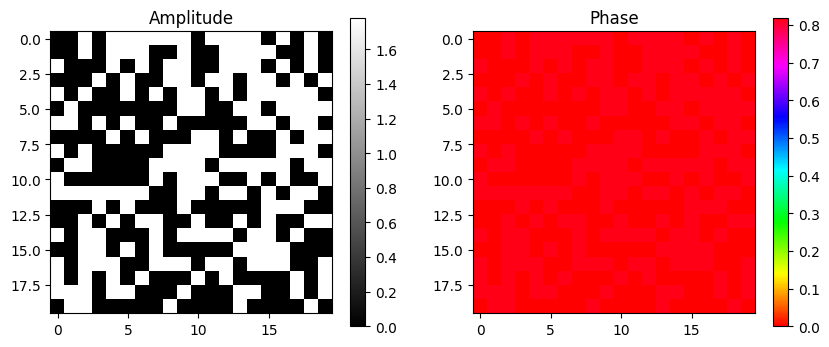

In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(input_field), cmap='gray')
plt.title("Amplitude")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(np.angle(input_field), cmap='hsv')
plt.title("Phase")
plt.colorbar()

plt.show()

In [29]:
test=input_field.flatten()
input_field.shape[0]-1, input_field.shape[0]

(19, 20)

In [23]:
test.size

400

In [11]:
xx, yy = np.meshgrid(np.linspace(0, input_field.shape[0]-1, input_field.shape[0]), np.linspace(0, input_field.shape[1]-1, input_field.shape[1]))
pupil = np.zeros_like(input_field)
pupil[(xx-input_field.shape[0]/2)**2 + (yy-input_field.shape[1]/2)**2 <= (input_field.shape[0]/2)**2] = 1

In [12]:
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

(20, 20)

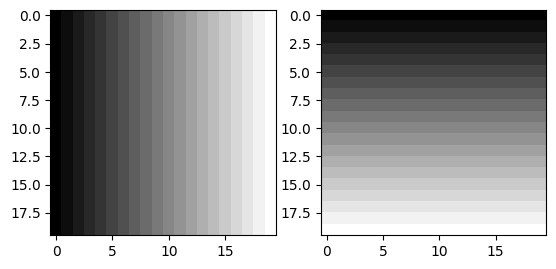

In [13]:
plt.subplot(1, 2, 1)
plt.imshow(xx, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(yy, cmap='gray')
xx.shape

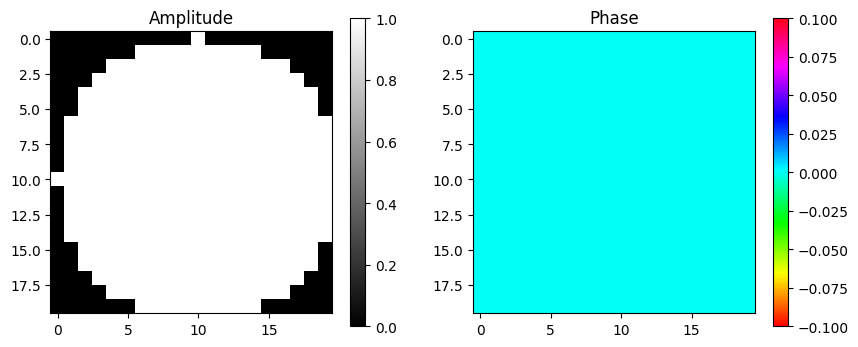

In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(pupil), cmap='gray')
plt.title("Amplitude")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(np.angle(pupil), cmap='hsv')
plt.title("Phase")
plt.colorbar()

plt.show()

In [41]:
m=np.random.rand(int(s_in[0]*s_in[1]), int(s_in[0]*s_in[1]))
m.shape

(400, 400)

In [9]:
import os
os.getcwd()

'/home/jingyehuang/jy RC'